In [ ]:
!pip install transformers torch scikit-learn

In [ ]:
!pip install "datasets<2.20.0"

INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 9.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Fo

In [ ]:
from datasets import load_dataset
import pandas as pd
from sklearn.model_selection import train_test_split

print("Baixando os arquivos de treino e teste ")
dataset_train = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"train": "mental_heath_unbanlanced.csv"})
dataset_test = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"test": "mental_health_combined_test.csv"})

df_train = pd.DataFrame(dataset_train['train'])
df_test = pd.DataFrame(dataset_test['test'])

print("Consolidando os dados em um único DataFrame")
df_total = pd.concat([df_train, df_test], ignore_index=True)

print("Filtrando classes para classificação binária (Depression e Normal)")
df_total = df_total[df_total['status'].isin(['Depression', 'Normal'])].copy()

df_total['label'] = df_total['status'].map({'Normal': 0, 'Depression': 1})
df_total = df_total.rename(columns={'text': 'texto_limpo'})

print("Realizando a divisão estratificada (80% Treino / 20% Teste)...")
df_treino, df_teste = train_test_split(
    df_total,
    test_size=0.20,
    random_state=42,
    stratify=df_total['label']
)

print(f" Treino: {len(df_treino)} textos | Teste: {len(df_teste)} textos.")

Baixando os arquivos de treino e teste da Ourafla para o RoBERTa 2...


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Consolidando os dados em um único DataFrame...
Filtrando classes para classificação binária (Depression e Normal)...
Realizando a divisão estratificada (80% Treino / 20% Teste)...
Base RoBERTa 2 pronta! Treino: 26714 textos | Teste: 6679 textos.


In [ ]:
from transformers import RobertaTokenizer

print("\nBaixando e carregando o Tokenizador")
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

print("\nConvertendo textos da base  em tokens (tamanho máximo de 128)")
#
train_encodings = tokenizer(df_treino['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
test_encodings = tokenizer(df_teste['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)

print("Tokenização realizada ")


Baixando e carregando o Tokenizador do RoBERTa...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]


Convertendo textos da base Ourafla em tokens (tamanho máximo de 128)...
Tokenização do RoBERTa 2 realizada com sucesso!


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import RobertaForSequenceClassification

class RedditDepressionDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

print("Envelopando os dados")
train_dataset = RedditDepressionDataset(train_encodings, df_treino['label'].tolist())
test_dataset = RedditDepressionDataset(test_encodings, df_teste['label'].tolist())

print("Criando os DataLoader")
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("\nBaixando o modelo ")
modelo_roberta = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=2)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
modelo_roberta.to(device)

print(f"Modelo carregado e enviado para a unidade: {device}")

Envelopando os dados matemáticos da Ourafla (Dataset)...
Criando os DataLoaders...

Baixando o modelo RoBERTa para Classificação...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo RoBERTa 2 carregado e enviado para a unidade: cuda


In [ ]:
from torch.optim import AdamW
import time


optimizer = AdamW(modelo_roberta.parameters(), lr=2e-5)
epochs = 3

print("Iniciando o treinamento ")

for epoch in range(epochs):
    print(f"\n--- Época {epoch+1} de {epochs} ---")
    modelo_roberta.train()
    total_loss = 0
    start_time = time.time()

    for step, batch in enumerate(train_loader):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        # Forward Pass
        outputs = modelo_roberta(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        # Backward Pass
        loss.backward()

        # Atualização de pesos
        optimizer.step()

        if step % 50 == 0 and not step == 0:
            print(f"  Lote {step} de {len(train_loader)} processados.")

    avg_loss = total_loss / len(train_loader)
    tempo_gasto = time.time() - start_time
    print(f"Época {epoch+1} concluída. Perda média: {avg_loss:.4f} | Tempo: {tempo_gasto:.2f}s")

print("\nTreinamento  finalizado ")

Iniciando o treinamento do RoBERTa 2 (Base Ourafla)...

--- Época 1 de 3 ---
  Lote 50 de 835 processados.
  Lote 100 de 835 processados.
  Lote 150 de 835 processados.
  Lote 200 de 835 processados.
  Lote 250 de 835 processados.
  Lote 300 de 835 processados.
  Lote 350 de 835 processados.
  Lote 400 de 835 processados.
  Lote 450 de 835 processados.
  Lote 500 de 835 processados.
  Lote 550 de 835 processados.
  Lote 600 de 835 processados.
  Lote 650 de 835 processados.
  Lote 700 de 835 processados.
  Lote 750 de 835 processados.
  Lote 800 de 835 processados.
Época 1 concluída! Perda média: 0.1307 | Tempo: 599.58s

--- Época 2 de 3 ---
  Lote 50 de 835 processados.
  Lote 100 de 835 processados.
  Lote 150 de 835 processados.
  Lote 200 de 835 processados.
  Lote 250 de 835 processados.
  Lote 300 de 835 processados.
  Lote 350 de 835 processados.
  Lote 400 de 835 processados.
  Lote 450 de 835 processados.
  Lote 500 de 835 processados.
  Lote 550 de 835 processados.
  Lote 600

Iniciando a avaliação do RoBERTa 2 na base consolidada (Ourafla)...

--- Resultados Finais: RoBERTa 2 (Ourafla) ---
Acurácia:  0.9765
Precisão:  0.9732
Revocação: 0.9736 (Sensibilidade)
F1-Score:  0.9734

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98      3728
  Depression       0.97      0.97      0.97      2951

    accuracy                           0.98      6679
   macro avg       0.98      0.98      0.98      6679
weighted avg       0.98      0.98      0.98      6679



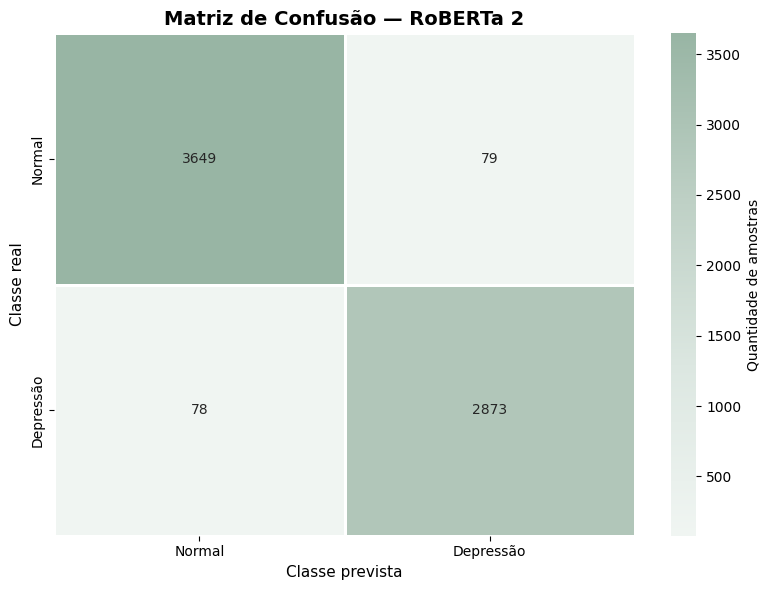

In [ ]:
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap


print("Iniciando a avaliação")



modelo_roberta.eval()

previsoes_r2 = []
gabarito_r2 = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        # Forward Pass
        outputs = modelo_roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        # Tomada de decisão
        preds = torch.argmax(
            logits,
            dim=1
        ).cpu().numpy()

        previsoes_r2.extend(preds)
        gabarito_r2.extend(labels.cpu().numpy())


# CÁLCULO DAS MÉTRICAS
acc = accuracy_score(
    gabarito_r2,
    previsoes_r2
)

prec = precision_score(
    gabarito_r2,
    previsoes_r2
)

rec = recall_score(
    gabarito_r2,
    previsoes_r2
)

f1 = f1_score(
    gabarito_r2,
    previsoes_r2
)


print("\n Resultados Finais")

print(f"Acurácia:  {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Revocação: {rec:.4f} (Sensibilidade)")
print(f"F1-Score:  {f1:.4f}")


print("\nRelatório de Classificação Detalhado:")

print(
    classification_report(
        gabarito_r2,
        previsoes_r2,
        target_names=['Normal', 'Depression']
    )
)



#  MATRIZ DE CONFUSÃO

cm = confusion_matrix(
    gabarito_r2,
    previsoes_r2
)


#CORES

cor_roberta2 = "#98B5A4"

cores_roberta2 = [
    "#F0F5F2",
    "#DCE7E1",
    "#BED0C5",
    "#98B5A4"
]

cmap_roberta2 = LinearSegmentedColormap.from_list(
    "RoBERTa2",
    cores_roberta2
)



# GRÁFICO


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=cmap_roberta2,
    xticklabels=['Normal', 'Depressão'],
    yticklabels=['Normal', 'Depressão'],
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Quantidade de amostras'}
)


plt.ylabel(
    'Classe real',
    fontsize=11
)

plt.xlabel(
    'Classe prevista',
    fontsize=11
)

plt.title(
    'Matriz de Confusão — RoBERTa 2',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

Gerando o gráfico da Curva ROC do RoBERTa 2...

AUC Final: 0.9966


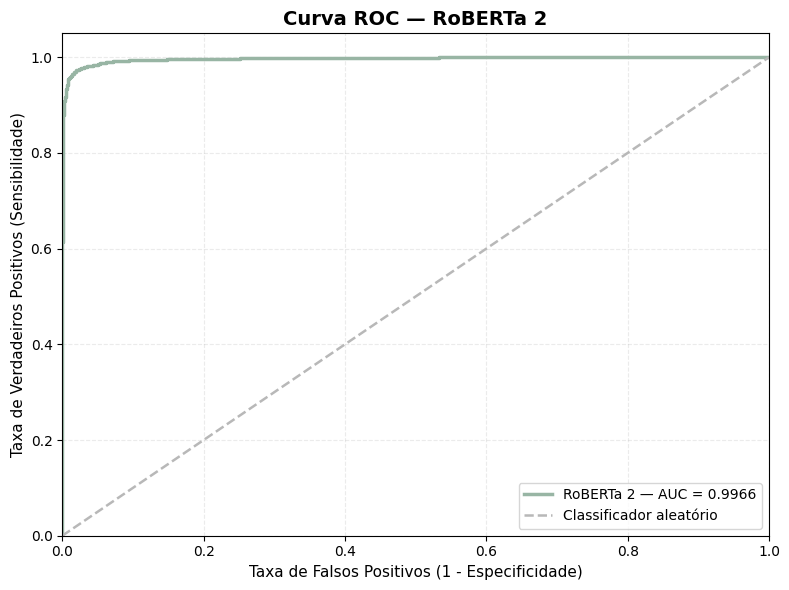


Gráfico gerado com sucesso! AUC Final: 0.9966


In [ ]:
import torch
import numpy as np

from sklearn.metrics import roc_curve, roc_auc_score

import matplotlib.pyplot as plt
import torch.nn.functional as F


print("Gerando o gráfico da Curva ROC")



modelo_roberta.eval()

probabilidades = []
gabarito_roc = []


with torch.no_grad():

    for batch in test_loader:

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        probs = F.softmax(logits, dim=1)

        probabilidades.extend(
            probs[:, 1].cpu().numpy()
        )

        gabarito_roc.extend(
            labels.cpu().numpy()
        )


# CÁLCULO DAS MÉTRICAS


roc_auc = roc_auc_score(
    gabarito_roc,
    probabilidades
)

fpr, tpr, _ = roc_curve(
    gabarito_roc,
    probabilidades
)


print(f"\nAUC Final: {roc_auc:.4f}")


#CORES

cor_roberta2 = "#98B5A4"
cor_neutra = "#B8B8B8"


# PLOTAGEM DA CURVA ROC


plt.figure(figsize=(8, 6))


# Curva ROC
plt.plot(
    fpr,
    tpr,
    color=cor_roberta2,
    lw=2.5,
    label=f'RoBERTa 2 — AUC = {roc_auc:.4f}'
)


# Classificador aleatório
plt.plot(
    [0, 1],
    [0, 1],
    color=cor_neutra,
    lw=1.8,
    linestyle='--',
    label='Classificador aleatório'
)


#  FORMATAÇÃO

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel(
    'Taxa de Falsos Positivos (1 - Especificidade)',
    fontsize=11
)

plt.ylabel(
    'Taxa de Verdadeiros Positivos (Sensibilidade)',
    fontsize=11
)

plt.title(
    'Curva ROC',
    fontsize=14,
    fontweight='bold'
)

plt.legend(
    loc="lower right",
    frameon=True
)

plt.grid(
    True,
    linestyle='--',
    alpha=0.25
)

plt.tight_layout()
plt.show()


print(
    f"\nGráfico gerado. AUC Final: {roc_auc:.4f}"
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
TEXTO ANALISADO
in zombie mode today kid are ill and kept me up till 0am up for work at am

RÓTULO REAL
Não Depressivo

PROBABILIDADES PREVISTAS
Não Depressivo: 0.9998
Depressivo:     0.0002

CLASSE PREVISTA
Não Depressivo


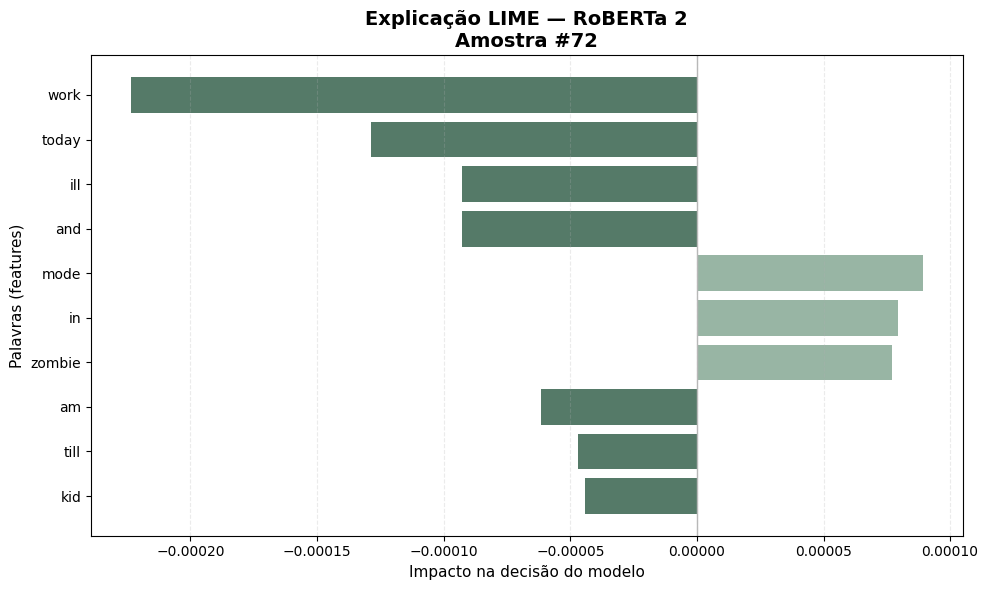

In [ ]:

# LIME

!pip install lime -q



from lime.lime_text import LimeTextExplainer

import numpy as np
import torch
import matplotlib.pyplot as plt

from IPython.display import display, HTML




def predict_proba_roberta2(textos):

    modelo_roberta.eval()

    probabilidades = []

    with torch.no_grad():

        for texto in textos:

            # Tokenização do texto
            encoding = tokenizer(
                texto,
                truncation=True,
                padding='max_length',
                max_length=128,
                return_tensors='pt'
            )


            input_ids = encoding['input_ids'].to(device)
            attention_mask = encoding['attention_mask'].to(device)

            outputs = modelo_roberta(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probs = torch.softmax(
                outputs.logits,
                dim=1
            )

            probabilidades.append(
                probs.cpu().numpy()[0]
            )

    return np.array(probabilidades)


# CRIAÇÃO DO EXPLICADOR LIME


explainer = LimeTextExplainer(
    class_names=[
        'Não Depressivo',
        'Depressivo'
    ],
    random_state=42
)


# ESCOLHA DA AMOSTRA


idx = 72

texto_amostra = str(
    df_teste.iloc[idx]['texto_limpo']
)

rotulo_real = int(
    df_teste.iloc[idx]['label']
)

print("============================================================")
print("TEXTO ANALISADO")
print("============================================================")

print(texto_amostra)

print("\n============================================================")
print("RÓTULO REAL")
print("============================================================")

if rotulo_real == 1:
    print("Depressivo")
else:
    print("Não Depressivo")




exp = explainer.explain_instance(
    texto_amostra,
    predict_proba_roberta2,
    num_features=10,
    num_samples=500
)


probabilidades = predict_proba_roberta2(
    [texto_amostra]
)[0]

print("PROBABILIDADES PREVISTAS")


print(
    f"Não Depressivo: {probabilidades[0]:.4f}"
)

print(
    f"Depressivo:     {probabilidades[1]:.4f}"
)



# RESULTADO DA CLASSIFICAÇÃO


classe_prevista = np.argmax(probabilidades)

print("\n============================================================")
print("CLASSE PREVISTA")
print("============================================================")

if classe_prevista == 1:
    print("Depressivo")
else:
    print("Não Depressivo")



# PALAVRAS MAIS IMPORTANTES

lista_lime = exp.as_list()

palavras = [
    item[0]
    for item in lista_lime
]

pesos = [
    item[1]
    for item in lista_lime
]



# CORES

cor_roberta2 = "#98B5A4"

cor_roberta1 = "#557A68"

cor_neutra = "#B8B8B8"




cores = [
    cor_roberta2 if peso > 0 else cor_roberta1
    for peso in pesos
]



#  GRÁFICO LIME


plt.figure(figsize=(10, 6))

plt.barh(
    palavras[::-1],
    pesos[::-1],
    color=cores[::-1]
)

plt.axvline(
    0,
    color=cor_neutra,
    linewidth=1
)

plt.title(
    "Explicação LIME — RoBERTa 2\nAmostra #72",
    fontsize=14,
    fontweight='bold'
)

plt.xlabel(
    "Impacto na decisão do modelo",
    fontsize=11
)

plt.ylabel(
    "Palavras (features)",
    fontsize=11
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)

plt.tight_layout()

plt.show()



#  EXIBIÇÃO DO LIME

display(
    HTML(
        """
        <style>
        .lime.top_div {
            width: 100% !important;
        }
        </style>
        """
    )
)

exp.show_in_notebook(text=True)